In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from src.config import *
from src.utils import *
from src.experiments import run_experiment, show, CV
from src.experiments import oof_predictions


In [2]:
train = pd.read_csv(MULTI_FEATURES_TRAIN_CSV)
feature_cols = [c for c in train.columns if c not in ("filename", "label")]
X, y = train[feature_cols].values, train["label"].values

counts = train["label"].map(MULTI_CLASS_NAMES).value_counts()
print(pd.DataFrame({"images": counts, "%": (100 * counts / counts.sum()).round(1)}))

prefix = train["filename"].str.replace(r"\d+\.jpg$", "", regex=True)
print("Filename prefix matches class:", (prefix == train["label"].map(MULTI_CLASS_FOLDERS)).all())
print("NaN / inf:", train[feature_cols].isna().sum().sum(), np.isinf(train[feature_cols].values).sum())

       images     %
label              
mel      2713  53.4
bcc      1993  39.2
scc       376   7.4
Filename prefix matches class: True
NaN / inf: 0 0


seed: 650


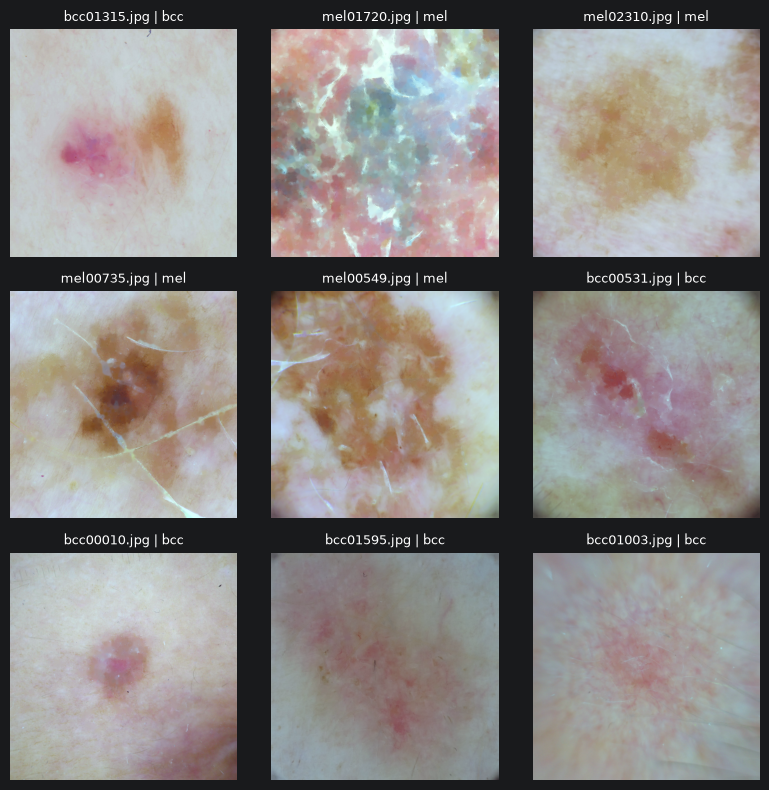

In [3]:
gt_train = pd.read_csv(MULTI_GT_TRAIN_CSV)
sample = random_sample(gt_train)
images = [load_preprocessed(r.filename, r.label, MULTI_PREPROC_TRAIN_DIR, MULTI_CLASS_FOLDERS)
          for r in sample.itertuples()]
show_grid(images, [f"{r.filename} | {MULTI_CLASS_NAMES[r.label]}" for r in sample.itertuples()])

In [4]:
table_m0, fitted_m0 = run_experiment("M0 no handling", X, y, task="multiclass")
show(table_m0, task="multiclass")

[M0 no handling] LogReg: kappa = 0.635
[M0 no handling] Random Forest: kappa = 0.658
[M0 no handling] HistGradBoost: kappa = 0.683
[M0 no handling] SVM (RBF): kappa = 0.720
[M0 no handling] XGBoost: kappa = 0.694
[M0 no handling] CatBoost: kappa = 0.686


,experiment,model,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
0,M0 no handling,LogReg,0.635 ± 0.024,0.876 ± 0.022,0.826 ± 0.024,0.152 ± 0.054,0.625 ± 0.030
1,M0 no handling,Random Forest,0.658 ± 0.011,0.897 ± 0.012,0.859 ± 0.016,0.037 ± 0.017,0.586 ± 0.009
2,M0 no handling,HistGradBoost,0.683 ± 0.010,0.899 ± 0.015,0.867 ± 0.017,0.138 ± 0.046,0.645 ± 0.019
3,M0 no handling,SVM (RBF),0.720 ± 0.015,0.923 ± 0.013,0.838 ± 0.022,0.367 ± 0.054,0.736 ± 0.014
4,M0 no handling,XGBoost,0.694 ± 0.010,0.905 ± 0.017,0.865 ± 0.020,0.181 ± 0.032,0.666 ± 0.013
5,M0 no handling,CatBoost,0.686 ± 0.012,0.902 ± 0.020,0.870 ± 0.015,0.125 ± 0.042,0.639 ± 0.017


In [5]:
table_m1, fitted_m1 = run_experiment("M1 class weights", X, y, task="multiclass", weighted=True)
show(table_m1, task="multiclass")

[M1 class weights] LogReg: kappa = 0.635
[M1 class weights] Random Forest: kappa = 0.665
[M1 class weights] HistGradBoost: kappa = 0.694
[M1 class weights] SVM (RBF): kappa = 0.717
[M1 class weights] XGBoost: kappa = 0.697
[M1 class weights] CatBoost: kappa = 0.687


,experiment,model,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
0,M1 class weights,LogReg,0.635 ± 0.024,0.876 ± 0.022,0.826 ± 0.024,0.152 ± 0.054,0.625 ± 0.030
1,M1 class weights,Random Forest,0.665 ± 0.021,0.871 ± 0.021,0.867 ± 0.013,0.191 ± 0.028,0.660 ± 0.014
2,M1 class weights,HistGradBoost,0.694 ± 0.012,0.902 ± 0.017,0.868 ± 0.015,0.186 ± 0.047,0.668 ± 0.018
3,M1 class weights,SVM (RBF),0.717 ± 0.017,0.926 ± 0.016,0.839 ± 0.020,0.327 ± 0.065,0.724 ± 0.022
4,M1 class weights,XGBoost,0.697 ± 0.012,0.890 ± 0.018,0.864 ± 0.013,0.287 ± 0.031,0.700 ± 0.012
5,M1 class weights,CatBoost,0.687 ± 0.015,0.898 ± 0.022,0.869 ± 0.015,0.159 ± 0.047,0.655 ± 0.017


In [6]:
results = pd.concat([table_m0, table_m1], ignore_index=True)
results.to_csv(RESULTS_DIR / "multi_exp_baseline.csv", index=False)

display(show(results, task="multiclass"))

# alpha chosen by CV for each weighted model
print(table_m1.set_index("model")["params"].map(lambda p: p.get("clf__alpha")))

best = results.loc[results["kappa"].idxmax()]
print(f"\nBest by CV kappa: {best['model']} ({best['experiment']}) - kappa {best['kappa']:.3f}")

,experiment,model,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
0,M0 no handling,LogReg,0.635 ± 0.024,0.876 ± 0.022,0.826 ± 0.024,0.152 ± 0.054,0.625 ± 0.030
1,M0 no handling,Random Forest,0.658 ± 0.011,0.897 ± 0.012,0.859 ± 0.016,0.037 ± 0.017,0.586 ± 0.009
2,M0 no handling,HistGradBoost,0.683 ± 0.010,0.899 ± 0.015,0.867 ± 0.017,0.138 ± 0.046,0.645 ± 0.019
3,M0 no handling,SVM (RBF),0.720 ± 0.015,0.923 ± 0.013,0.838 ± 0.022,0.367 ± 0.054,0.736 ± 0.014
4,M0 no handling,XGBoost,0.694 ± 0.010,0.905 ± 0.017,0.865 ± 0.020,0.181 ± 0.032,0.666 ± 0.013
5,M0 no handling,CatBoost,0.686 ± 0.012,0.902 ± 0.020,0.870 ± 0.015,0.125 ± 0.042,0.639 ± 0.017
6,M1 class weights,LogReg,0.635 ± 0.024,0.876 ± 0.022,0.826 ± 0.024,0.152 ± 0.054,0.625 ± 0.030
7,M1 class weights,Random Forest,0.665 ± 0.021,0.871 ± 0.021,0.867 ± 0.013,0.191 ± 0.028,0.660 ± 0.014
8,M1 class weights,HistGradBoost,0.694 ± 0.012,0.902 ± 0.017,0.868 ± 0.015,0.186 ± 0.047,0.668 ± 0.018
9,M1 class weights,SVM (RBF),0.717 ± 0.017,0.926 ± 0.016,0.839 ± 0.020,0.327 ± 0.065,0.724 ± 0.022


model
LogReg           0.00
Random Forest    0.75
HistGradBoost    0.50
SVM (RBF)        0.75
XGBoost          1.00
CatBoost         0.25
Name: params, dtype: float64

Best by CV kappa: SVM (RBF) (M0 no handling) - kappa 0.720


In [8]:
top2 = results.nlargest(2, "kappa")
oof = {}
for r in top2.itertuples():
    key = (r.experiment, r.model)
    oof[key] = oof_predictions(fitted[key], X, y)
    print("done:", key)

done: ('M0 no handling', 'SVM (RBF)')
done: ('M1 class weights', 'SVM (RBF)')


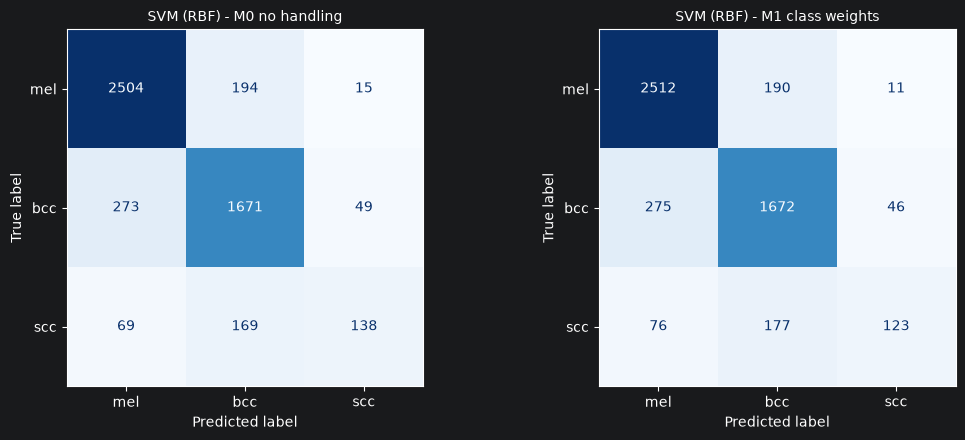

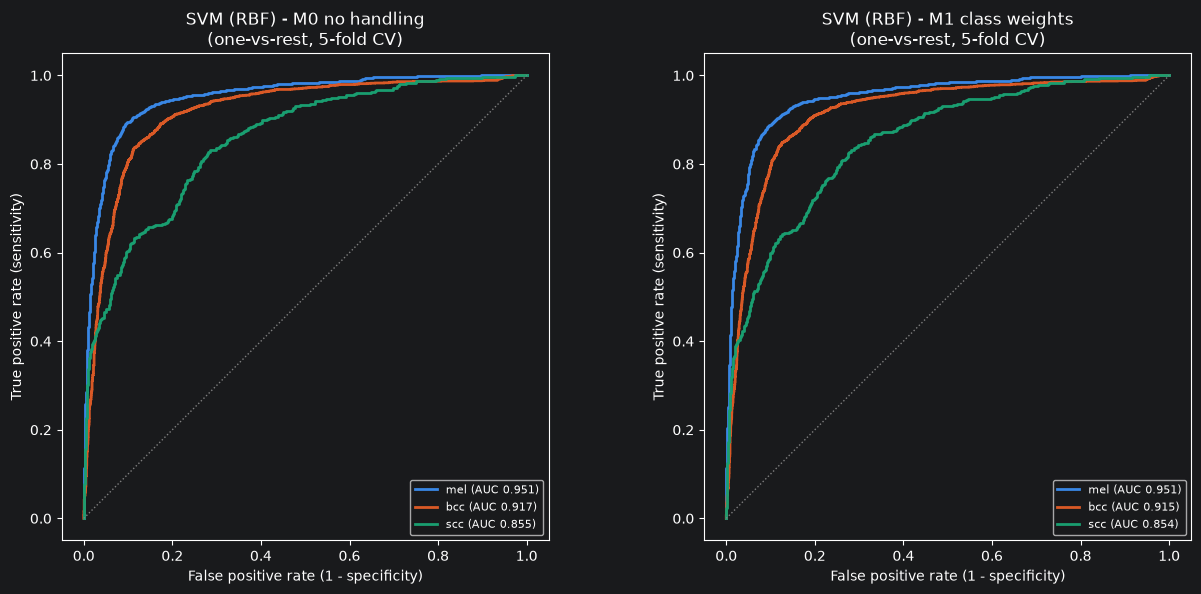

In [11]:
# Show the conf. matrices for the unbalanced and weighted balancing strategies of SVM (the two best models):
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ((exp, model), (pred, _)) in zip(axes, oof.items()):
    plot_confusion(ax, y, pred, f"{model} - {exp}", class_names=MULTI_CLASS_NAMES.values())
plt.tight_layout()
plt.show()

# Plot the ROC curves of these two best models:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, ((exp, model), (_, scores)) in zip(axes, oof.items()):
    for label, name in MULTI_CLASS_NAMES.items():
        plot_roc(ax, (y == label).astype(int), scores[:, label], name, MULTI_CLASS_COLORS[label])
    finish_roc(ax, f"{model} - {exp}\n(one-vs-rest, 5-fold CV)")
plt.tight_layout()
plt.show()

In [12]:
print(table_m0.set_index("model").loc["SVM (RBF)", "params"])
print(table_m1.set_index("model").loc["SVM (RBF)", "params"])

{'clf__C': np.float64(6.358358856676251), 'clf__gamma': np.float64(0.013311216080736894)}
{'clf__alpha': 0.75, 'clf__estimator__C': np.float64(71.14476009343416), 'clf__estimator__gamma': np.float64(0.015702970884055395)}
